<a href="https://colab.research.google.com/github/tyangdon/Opportunity_Execelerate_file-/blob/main/Excelerate_Task_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import re
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
# pd.set_option('display.max_rows', None)

In [ ]:
df = pd.read_excel('/content/Opportunity_Cleaned_Dataset.xlsx')
print("Data set shape is ", df.shape)
df.head(3)

Data set shape is  (5418, 15)


,opportunity_id,category,created_at,currency_type,duration,duration_type,fee,is_auto_approve,last_date_to_apply,location,long_description,microscholarship,modified_at,name,short_description
0,Opportunity#000000000GBD0AX3Z6VYRG7R75,Competition,2022-08-08 23:06:40+00:00,USD,300,minutes,0.0,True,2023-07-22 04:26:40+00:00,Virtual,"Your future is in your hands, truly. Ideate an...",500.0,2023-07-22 04:26:40+00:00,Mini Saga 3.0,Express yourself in 50-words!
1,Opportunity#000000000GFKZ4N696ZF8V2WM8,Career,2022-08-08 23:06:40+00:00,USD,1,years,0.0,True,2023-07-22 04:26:40+00:00,Virtual,At GlobalShala we believe that experiential le...,100.0,2023-07-22 04:26:40+00:00,Virtual Internship Facilitator,In this role you be impacting young lives whil...
2,Opportunity#0000000010ZFE0ZS22FA3Q62R4,Career,2024-03-09 16:00:00+00:00,USD,30,weeks,0.0,False,2019-06-08 13:20:00+00:00,Virtual,Not provided,0.0,2024-03-09 16:00:00+00:00,Careerwishlist Automation 1710333189352,"Short Description, Explore hands-on defensive ..."


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5418 entries, 0 to 5417
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   opportunity_id      5418 non-null   object 
 1   category            5418 non-null   object 
 2   created_at          5418 non-null   object 
 3   currency_type       5418 non-null   object 
 4   duration            5418 non-null   int64  
 5   duration_type       5418 non-null   object 
 6   fee                 5418 non-null   float64
 7   is_auto_approve     5418 non-null   bool   
 8   last_date_to_apply  5418 non-null   object 
 9   location            5418 non-null   object 
 10  long_description    5418 non-null   object 
 11  microscholarship    5418 non-null   float64
 12  modified_at         5418 non-null   object 
 13  name                5418 non-null   object 
 14  short_description   5418 non-null   object 
dtypes: bool(1), float64(2), int64(1), object(11)
memory usa

# Microsholarship Variable for USD

In [ ]:
# Assuming your currency column is named 'currency_type' and the fee column is 'fee'
max_microscholarship_by_currency = df.groupby('currency_type')['microscholarship'].max().reset_index()

# Display the results
print("--- Maximum scholarship by Currency Type ---")
display(max_microscholarship_by_currency)

--- Maximum scholarship by Currency Type ---


,currency_type,microscholarship
0,EUR,14525.0
1,INR,500000000.0
2,USD,10000000.0


In [ ]:
# Filter for USD currency type
usd_fees = df[df['currency_type'] == 'USD']['microscholarship']

# Calculate mean and median
usd_mean = usd_fees.mean()
usd_median = usd_fees.median()
usd_mode = usd_fees.mode()
usd_max= usd_fees.max()
usd_min= usd_fees.min()

print(f"Mean USD Fee: {usd_mean}")
print(f"Median USD Fee: {usd_median}")
print(f"Mode USD Fee: {usd_mode}")
print(f'Maximum INR Fee: {usd_max}')
print(f'Minimum INR Fee: {usd_min}')

Mean USD Fee: 2226.1661184210525
Median USD Fee: 120.0
Mode USD Fee: 0    120.0
Name: microscholarship, dtype: float64
Maximum INR Fee: 10000000.0
Minimum INR Fee: 0.0


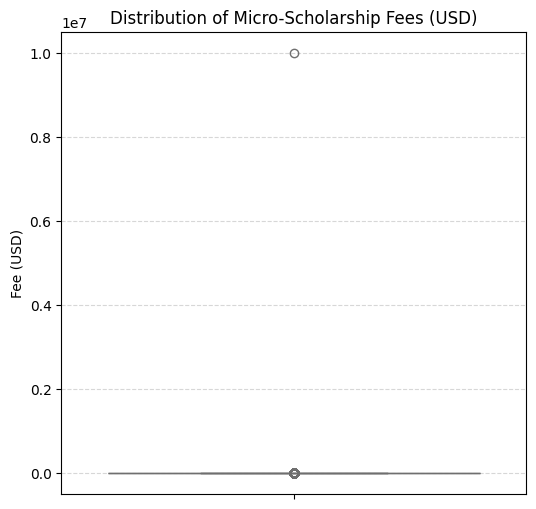

In [ ]:
# Filter for USD currency type
usd_fees = df[df['currency_type'] == 'USD']['microscholarship'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=usd_fees, color='skyblue')

plt.title('Distribution of Micro-Scholarship Fees (USD)')
plt.ylabel('Fee (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
print(usd_fees.sort_values(ascending=False).head(10))
print(usd_fees.describe(percentiles=[.5, .75, .9, .95, .99]))

1690    10000000.0
361        10048.0
3770        6700.0
2428        6000.0
5139        3435.0
1908        3000.0
2129        3000.0
495         3000.0
2448        3000.0
3011        3000.0
Name: microscholarship, dtype: float64
count    4.864000e+03
mean     2.226166e+03
std      1.433830e+05
min      0.000000e+00
50%      1.200000e+02
75%      1.200000e+02
90%      1.200000e+02
95%      2.000000e+02
99%      3.000000e+03
max      1.000000e+07
Name: microscholarship, dtype: float64


In [ ]:
usd_clean = usd_fees[usd_fees < 1_000_000]
print(usd_clean.describe())

count     4863.000000
mean       170.280074
std        427.037645
min          0.000000
25%        120.000000
50%        120.000000
75%        120.000000
max      10048.000000
Name: microscholarship, dtype: float64


**

Why 3,000:

It’s the 99th percentile of your original data, so you lose almost nothing.
It’s also a real fee tier (74 rows), so the cutoff lands on an actual value instead of an arbitrary number.
Only a handful of rows sit above it (10,048, 6,700, 6,000, 3,435), and they’re the sparse tail, not a pattern.**

In [ ]:
mask = (df['currency_type'] == 'USD') & (df['microscholarship'] > 3000)
print(mask.sum())                      # number of rows that will be clipped
print(mask.mean() * 100)

5
0.09228497600590624


In [ ]:
df.loc[(df['currency_type'] == 'USD') & (df['microscholarship'] > 3000), 'microscholarship'] = 3000

In [ ]:
# Filter for USD currency type
usd_fees = df[df['currency_type'] == 'USD']['microscholarship']

# Calculate mean and median
usd_mean = usd_fees.mean()
usd_median = usd_fees.median()
usd_mode = usd_fees.mode()
usd_max= usd_fees.max()
usd_min= usd_fees.min()

print(f"Mean USD Fee: {usd_mean}")
print(f"Median USD Fee: {usd_median}")
print(f"Mode USD Fee: {usd_mode}")
print(f'Maximum INR Fee: {usd_max}')
print(f'Minimum INR Fee: {usd_min}')

Mean USD Fee: 167.94592927631578
Median USD Fee: 120.0
Mode USD Fee: 0    120.0
Name: microscholarship, dtype: float64
Maximum INR Fee: 3000.0
Minimum INR Fee: 0.0


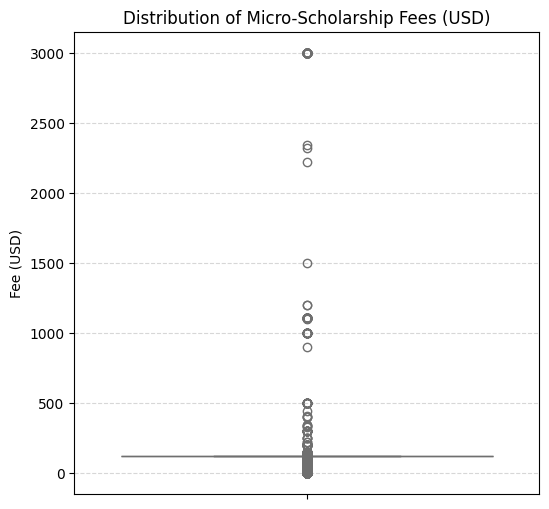

In [ ]:
# Filter for EUR currency type
usd_fees = df[df['currency_type'] == 'USD']['microscholarship'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=usd_fees, color='skyblue')

plt.title('Distribution of Micro-Scholarship Fees (USD)')
plt.ylabel('Fee (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# Microsholarship Variable for EUR

In [ ]:
# Filter for EUR currency type
eur_fees = df[df['currency_type'] == 'EUR']['microscholarship']

# Calculate mean and median
eur_mean = eur_fees.mean()
eur_median = eur_fees.median()
eur_mode = eur_fees.mode()
eur_max= eur_fees.max()
eur_min= eur_fees.min()

print(f"Mean eur Fee: {eur_mean}")
print(f"Median eur Fee: {eur_median}")
print(f"Mode eur Fee: {eur_mode}")
print(f'Maximum INR Fee: {eur_max}')
print(f'Minimum INR Fee: {eur_min}')

Mean eur Fee: 265.33098591549293
Median eur Fee: 19.5
Mode eur Fee: 0    0.0
Name: microscholarship, dtype: float64
Maximum INR Fee: 14525.0
Minimum INR Fee: 0.0


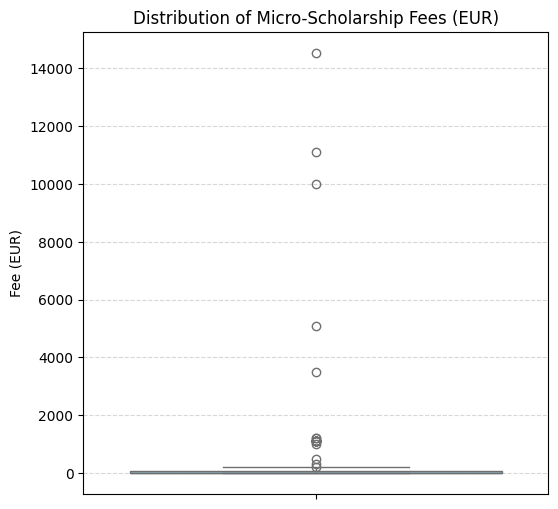

In [ ]:
# Filter for EUR currency type
eur_fees = df[df['currency_type'] == 'EUR']['microscholarship'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=eur_fees, color='skyblue')

plt.title('Distribution of Micro-Scholarship Fees (EUR)')
plt.ylabel('Fee (EUR)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
print(eur_fees.sort_values(ascending=False).head(10))
print(eur_fees.describe(percentiles=[.5, .75, .9, .95, .99]))

4229    14525.0
3315    11111.0
4764     9990.0
4500     5100.0
1053     3513.0
2725     1211.0
452      1200.0
362      1111.0
5396     1111.0
446      1111.0
Name: microscholarship, dtype: float64
count      284.000000
mean       265.330986
std       1298.846519
min          0.000000
50%         19.500000
75%         86.000000
90%        200.000000
95%       1111.000000
99%       5931.300000
max      14525.000000
Name: microscholarship, dtype: float64


**Why 1,500:

The values up to 1,500 look like real fees. Above that, there’s a jump to 1,211, then 3,513, 5,100, 9,990, 11,111 and 14,525, all far above the 90th percentile of 200.
It caps only 5 of 284 rows (about 2%).
It keeps the 1,111 tier intact. 1,111 appears at least 3 times in your top 10 and is the 95th percentile, so it’s a repeated value rather than a one-off.**

In [ ]:
mask = (df['currency_type'] == 'EUR') & (df['microscholarship'] > 1500)
print(mask.sum())                      # number of rows that will be clipped
print(mask.mean() * 100)

5
0.09228497600590624


In [ ]:
df.loc[(df['currency_type'] == 'EUR') & (df['microscholarship'] > 1500), 'microscholarship'] = 1500

In [ ]:
# Filter for EUR currency type
eur_fees = df[df['currency_type'] == 'EUR']['microscholarship']

# Calculate mean and median
eur_mean = eur_fees.mean()
eur_median = eur_fees.median()
eur_mode = eur_fees.mode()
eur_max= eur_fees.max()
eur_min= eur_fees.min()

print(f"Mean eur Fee: {eur_mean}")
print(f"Median eur Fee: {eur_median}")
print(f"Mode eur Fee: {eur_mode}")
print(f'Maximum INR Fee: {eur_max}')
print(f'Minimum INR Fee: {eur_min}')

Mean eur Fee: 135.96830985915494
Median eur Fee: 19.5
Mode eur Fee: 0    0.0
Name: microscholarship, dtype: float64
Maximum INR Fee: 1500.0
Minimum INR Fee: 0.0


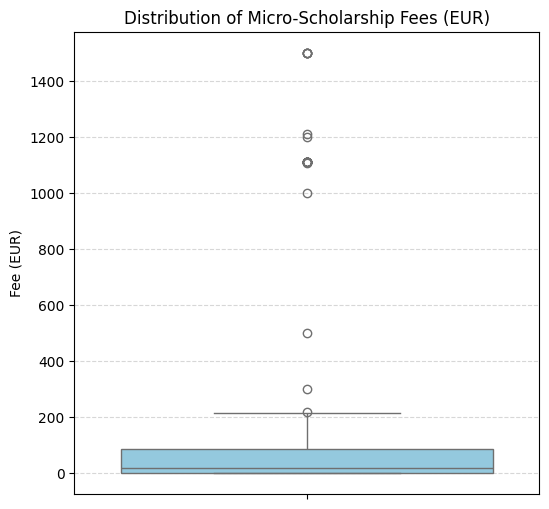

In [ ]:
# Filter for EUR currency type
eur_fees = df[df['currency_type'] == 'EUR']['microscholarship'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=eur_fees, color='skyblue')

plt.title('Distribution of Micro-Scholarship Fees (EUR)')
plt.ylabel('Fee (EUR)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# Microsholarship Variable for INR

In [ ]:
# Filter for INR currency type
inr_fees = df[df['currency_type'] == 'INR']['microscholarship']

# Calculate mean and median
inr_mean = inr_fees.mean()
inr_median = inr_fees.median()
inr_mode = inr_fees.mode()
inr_max= inr_fees.max()
inr_min= inr_fees.min()

print(f"Mean inr Fee: {inr_mean}")
print(f"Median inr Fee: {inr_median}")
print(f"Mode inr Fee: {inr_mode}")
print(f'Maximum INR Fee: {inr_max}')
print(f'Minimum INR Fee: {inr_min}')

Mean inr Fee: 1852144.211111111
Median inr Fee: 10.0
Mode inr Fee: 0    0.0
Name: microscholarship, dtype: float64
Maximum INR Fee: 500000000.0
Minimum INR Fee: 0.0


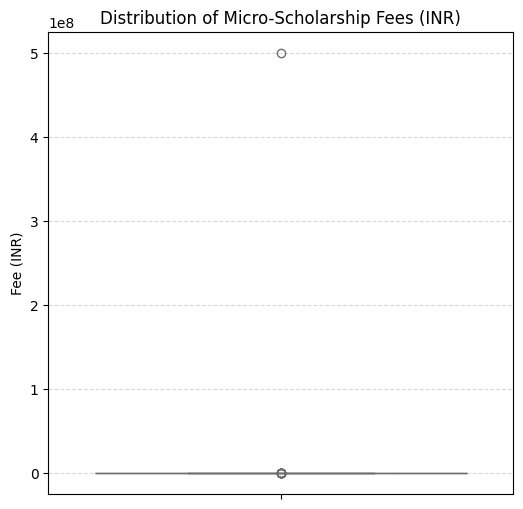

In [ ]:
# Filter for INR currency type
inr_fees = df[df['currency_type'] == 'INR']['microscholarship'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=inr_fees, color='skyblue')

plt.title('Distribution of Micro-Scholarship Fees (INR)')
plt.ylabel('Fee (INR)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
print(inr_fees.sort_values(ascending=False).head(10))
print(inr_fees.describe(percentiles=[.5, .75, .9, .95, .99]))

4736    500000000.0
3452        50000.0
3894         9999.0
4846         2000.0
314          1250.0
1994         1111.0
4656         1111.0
22           1000.0
4669         1000.0
3971         1000.0
Name: microscholarship, dtype: float64
count    2.700000e+02
mean     1.852144e+06
std      3.042901e+07
min      0.000000e+00
50%      1.000000e+01
75%      1.000000e+02
90%      1.000000e+02
95%      1.378500e+02
99%      4.479690e+03
max      5.000000e+08
Name: microscholarship, dtype: float64


In [ ]:
mask = (df['currency_type'] == 'INR') & (df['microscholarship'] > 4480)
print(mask.sum())                      # number of rows that will be clipped
print(mask.mean() * 100)               # percentage of all rows

3
0.05537098560354374


**Why 4,480:

It represents the 99th percentile of your original INR dataset, ensuring you retain over 99.9% of your valid data points and lose virtually nothing.It cleanly separates extreme, erroneous data entry spikes—such as the massive outlier of $500,000,000\text{ INR}$ (which mirrors the test/error strings seen in USD)—from the actual operating range of the dataset


In [ ]:
df.loc[(df['currency_type'] == 'INR') & (df['microscholarship'] > 4480), 'microscholarship'] = 4480

In [ ]:
# Filter for INR currency type
inr_fees = df[df['currency_type'] == 'INR']['microscholarship']

# Calculate mean and median
inr_mean = inr_fees.mean()
inr_median = inr_fees.median()
inr_mode = inr_fees.mode()
inr_max= inr_fees.max()
inr_min= inr_fees.min()

print(f"Mean inr Fee: {inr_mean}")
print(f"Median inr Fee: {inr_median}")
print(f"Mode inr Fee: {inr_mode}")
print(f'Maximum INR Fee: {inr_max}')
print(f'Minimum INR Fee: {inr_min}')

Mean inr Fee: 119.91851851851852
Median inr Fee: 10.0
Mode inr Fee: 0    0.0
Name: microscholarship, dtype: float64
Maximum INR Fee: 4480.0
Minimum INR Fee: 0.0


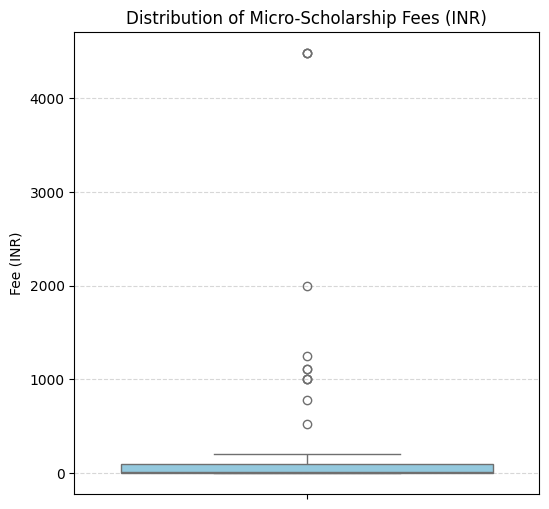

In [ ]:
#  Filter for INR currency type
inr_fees = df[df['currency_type'] == 'INR']['microscholarship'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=inr_fees, color='skyblue')

plt.title('Distribution of Micro-Scholarship Fees (INR)')
plt.ylabel('Fee (INR)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# FEES Variable for USD

In [ ]:
# Assuming your currency column is named 'currency_type' and the fee column is 'fee'
max_microscholarship_by_currency = df.groupby('currency_type')['fee'].max().reset_index()

# Display the results
print("--- Maximum Fee by Currency Type ---")
display(max_microscholarship_by_currency)

--- Maximum Fee by Currency Type ---


,currency_type,fee
0,EUR,6.000000e+02
1,INR,6.500000e+04
2,USD,6.000000e+12


In [ ]:
# Filter for USD currency type
usd_fees = df[df['currency_type'] == 'USD']['fee']

# Calculate mean and median
usd_mean = usd_fees.mean()
usd_median = usd_fees.median()
usd_mode = usd_fees.mode()
usd_max= usd_fees.max()
usd_min= usd_fees.min()

print(f"Mean USD Fee: {usd_mean}")
print(f"Median USD Fee: {usd_median}")
print(f"Mode USD Fee: {usd_mode}")
print(f'Maximum usd Fee: {usd_max}')
print(f'Minimum usd Fee: {usd_min}')

Mean USD Fee: 1233552683.4617598
Median USD Fee: 0.0
Mode USD Fee: 0    0.0
Name: fee, dtype: float64
Maximum usd Fee: 6000000000000.0
Minimum usd Fee: 0.0


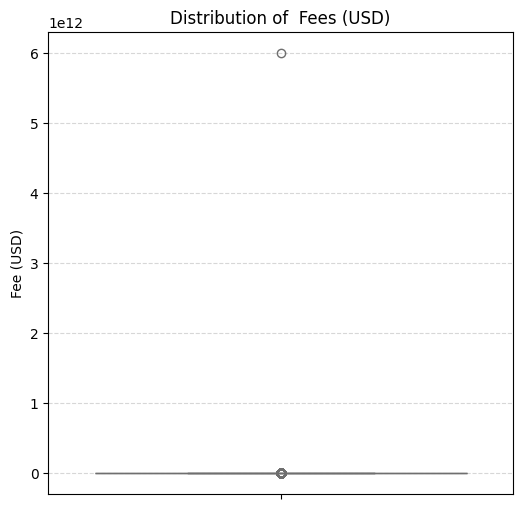

In [ ]:
# Filter for USD currency type
usd_fees = df[df['currency_type'] == 'USD']['fee'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=usd_fees, color='skyblue')

plt.title('Distribution of  Fees (USD)')
plt.ylabel('Fee (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
print(usd_fees.sort_values(ascending=False).head(10))
print(usd_fees.describe(percentiles=[.5, .75, .9, .95, .99]))

830     6.000000e+12
4698    2.000000e+05
1436    2.000000e+04
2809    2.345000e+03
2161    2.000000e+03
221     2.000000e+03
4701    2.000000e+03
542     1.234000e+03
2427    1.000000e+03
2183    5.000000e+02
Name: fee, dtype: float64
count    4.864000e+03
mean     1.233553e+09
std      8.603090e+10
min      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
90%      1.000000e+00
95%      2.085000e+01
99%      1.000000e+02
max      6.000000e+12
Name: fee, dtype: float64


In [ ]:
usd_clean = usd_fees[usd_fees < 1_000_000]
print(usd_clean.describe())

count      4863.000000
mean         51.893481
std        2882.916566
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max      200000.000000
Name: fee, dtype: float64


In [ ]:
mask = (df['currency_type'] == 'USD') & (df['fee'] > 3000)
print(mask.sum())                      # number of rows that will be clipped
print(mask.mean() * 100)

3
0.05537098560354374


In [ ]:
df.loc[(df['currency_type'] == 'USD') & (df['fee'] > 3000), 'fee'] = 3000

In [ ]:
# Filter for USD currency type
usd_fees = df[df['currency_type'] == 'USD']['fee']

# Calculate mean and median
usd_mean = usd_fees.mean()
usd_median = usd_fees.median()
usd_mode = usd_fees.mode()
usd_max= usd_fees.max()
usd_min= usd_fees.min()

print(f"Mean USD Fee: {usd_mean}")
print(f"Median USD Fee: {usd_median}")
print(f"Mode USD Fee: {usd_mode}")
print(f'Maximum usd Fee: {usd_max}')
print(f'Minimum usd Fee: {usd_min}')


Mean USD Fee: 8.502878289473685
Median USD Fee: 0.0
Mode USD Fee: 0    0.0
Name: fee, dtype: float64
Maximum usd Fee: 3000.0
Minimum usd Fee: 0.0


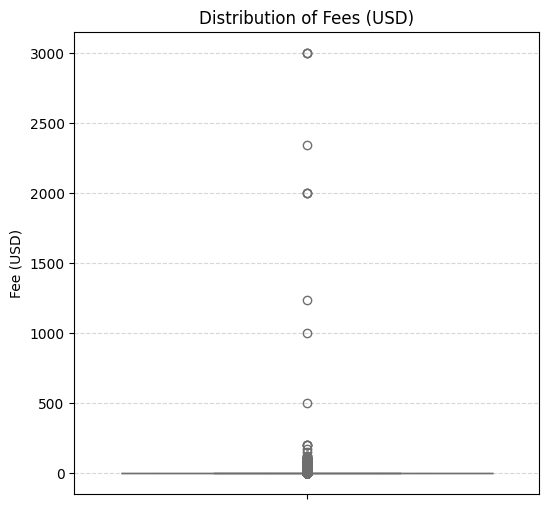

In [ ]:
# Filter for EUR currency type
usd_fees = df[df['currency_type'] == 'USD']['fee'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=usd_fees, color='skyblue')

plt.title('Distribution of Fees (USD)')
plt.ylabel('Fee (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# FEES Variable for EUR

In [ ]:
# Filter for eur currency type
eur_fees = df[df['currency_type'] == 'EUR']['fee']

# Calculate mean and median
eur_mean = eur_fees.mean()
eur_median = eur_fees.median()
eur_mode = eur_fees.mode()
eur_max= eur_fees.max()
eur_min= eur_fees.min()

print(f"Mean eur Fee: {eur_mean}")
print(f"Median eur Fee: {eur_median}")
print(f"Mode eur Fee: {eur_mode}")
print(f'Maximum INR Fee: {eur_max}')
print(f'Minimum INR Fee: {eur_min}')

Mean eur Fee: 14.204225352112676
Median eur Fee: 0.0
Mode eur Fee: 0    0.0
Name: fee, dtype: float64
Maximum INR Fee: 600.0
Minimum INR Fee: 0.0


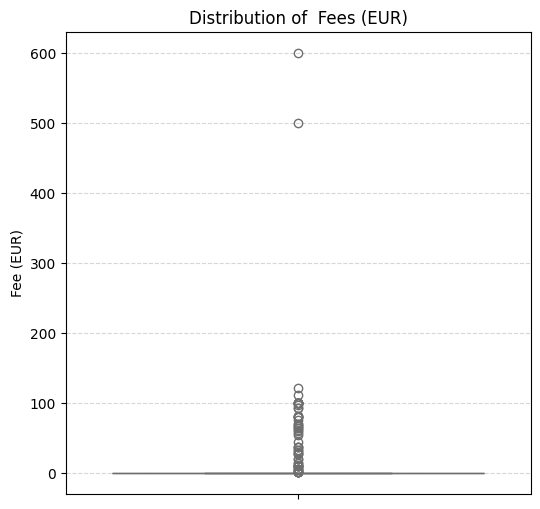

In [ ]:
# Filter for USD currency type
eur_fees = df[df['currency_type'] == 'EUR']['fee'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=eur_fees, color='skyblue')

plt.title('Distribution of  Fees (EUR)')
plt.ylabel('Fee (EUR)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
print(eur_fees.sort_values(ascending=False).head(10))
print(eur_fees.describe(percentiles=[.5, .75, .9, .95, .99]))

1948    600.0
597     500.0
1826    121.0
2319    111.0
468     100.0
333     100.0
3318    100.0
3307    100.0
418     100.0
3511    100.0
Name: fee, dtype: float64
count    284.000000
mean      14.204225
std       52.491633
min        0.000000
50%        0.000000
75%        0.000000
90%       59.400000
95%       91.350000
99%      112.700000
max      600.000000
Name: fee, dtype: float64


In [ ]:
mask = (df['currency_type'] == 'EUR') & (df['fee'] > 500)
print(mask.sum())                      # number of rows that will be clipped
print(mask.mean() * 100)

1
0.018456995201181246


In [ ]:
df.loc[(df['currency_type'] == 'EUR') & (df['fee'] > 500), 'fee'] = 500

In [ ]:
# Filter for EUR currency type
eur_fees = df[df['currency_type'] == 'EUR']['fee']

# Calculate mean and median
eur_mean = eur_fees.mean()
eur_median = eur_fees.median()
eur_mode = eur_fees.mode()
eur_max= eur_fees.max()
eur_min= eur_fees.min()

print(f"Mean eur Fee: {eur_mean}")
print(f"Median eur Fee: {eur_median}")
print(f"Mode eur Fee: {eur_mode}")
print(f'Maximum INR Fee: {eur_max}')
print(f'Minimum INR Fee: {eur_min}')

Mean eur Fee: 13.852112676056338
Median eur Fee: 0.0
Mode eur Fee: 0    0.0
Name: fee, dtype: float64
Maximum INR Fee: 500.0
Minimum INR Fee: 0.0


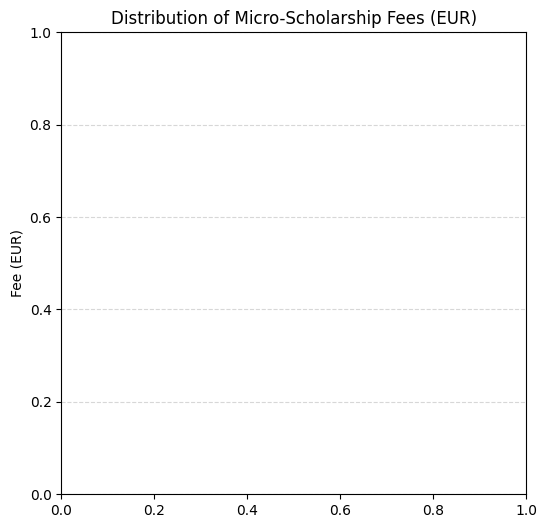

In [ ]:
# Filter for EUR currency type
eur_fees = df[df['currency_type'] == 'eur']['fee'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=eur_fees, color='skyblue')

plt.title('Distribution of Micro-Scholarship Fees (EUR)')
plt.ylabel('Fee (EUR)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# FEES Variable for INR

In [ ]:
# Filter for USD currency type
inr_fees = df[df['currency_type'] == 'INR']['fee']

# Calculate mean and median
inr_mean = inr_fees.mean()
inr_median = inr_fees.median()
inr_mode = inr_fees.mode()
inr_max= inr_fees.max()
inr_min= inr_fees.min()

print(f"Mean inr Fee: {inr_mean}")
print(f"Median inr Fee: {inr_median}")
print(f"Mode inr Fee: {inr_mode}")
print(f'Maximum inr Fee: {inr_max}')
print(f'Minimum inr Fee: {inr_min}')

Mean inr Fee: 261.46666666666664
Median inr Fee: 0.0
Mode inr Fee: 0    0.0
Name: fee, dtype: float64
Maximum inr Fee: 65000.0
Minimum inr Fee: 0.0


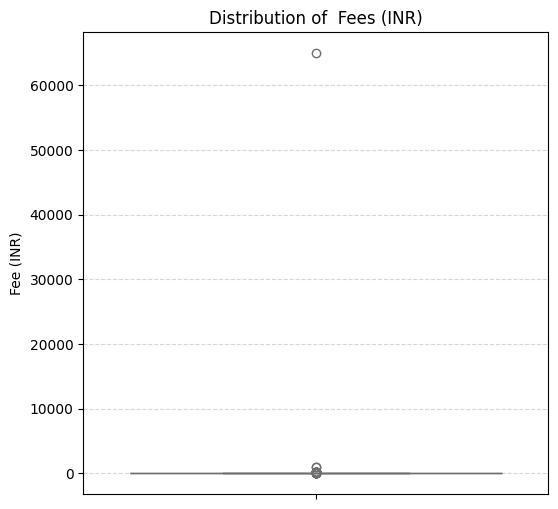

In [ ]:
# Filter for inr currency type
inr_fees = df[df['currency_type'] == 'INR']['fee'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=inr_fees, color='skyblue')

plt.title('Distribution of  Fees (INR)')
plt.ylabel('Fee (INR)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
print(inr_fees.sort_values(ascending=False).head(10))
print(inr_fees.describe(percentiles=[.5, .75, .9, .95, .99]))

3452    65000.0
3023     1000.0
4282     1000.0
1080      100.0
4640      100.0
4297      100.0
4295      100.0
3945      100.0
4722      100.0
934       100.0
Name: fee, dtype: float64
count      270.000000
mean       261.466667
std       3955.522705
min          0.000000
50%          0.000000
75%         10.000000
90%         84.000000
95%        100.000000
99%        379.000000
max      65000.000000
Name: fee, dtype: float64


In [ ]:
mask = (df['currency_type'] == 'INR') & (df['fee'] > 2000)
print(mask.sum())                      # number of rows that will be clipped
print(mask.mean() * 100)

1
0.018456995201181246


In [ ]:
df.loc[(df['currency_type'] == 'INR') & (df['fee'] > 2000), 'fee'] = 2000

In [ ]:
# Filter for INR currency type
inr_fees = df[df['currency_type'] == 'INR']['fee']

# Calculate mean and median
inr_mean = inr_fees.mean()
inr_median = inr_fees.median()
inr_mode = inr_fees.mode()
inr_max= inr_fees.max()
inr_min= inr_fees.min()

print(f"Mean inr Fee: {inr_mean}")
print(f"Median inr Fee: {inr_median}")
print(f"Mode inr Fee: {inr_mode}")
print(f'Maximum INR Fee: {inr_max}')
print(f'Minimum INR Fee: {inr_min}')

Mean inr Fee: 28.133333333333333
Median inr Fee: 0.0
Mode inr Fee: 0    0.0
Name: fee, dtype: float64
Maximum INR Fee: 2000.0
Minimum INR Fee: 0.0


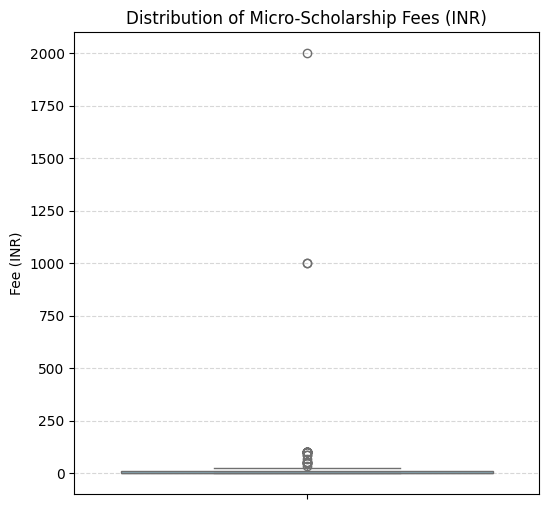

In [ ]:
# Filter for EUR currency type
irn_fees = df[df['currency_type'] == 'USD']['fee'].dropna()

plt.figure(figsize=(6, 6))
sns.boxplot(y=inr_fees, color='skyblue')

plt.title('Distribution of Micro-Scholarship Fees (INR)')
plt.ylabel('Fee (INR)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# Conversion of duration, duration_type into Duration_in_days

In [ ]:
# Days per unit
to_days = {
    "minutes": 1 / (24 * 60),
    "hours":   1 / 24,
    "days":    1,
    "weeks":   7,
    "months":  30,
    "years":   365,
}

df["duration_in_days"] = df["duration"] * df["duration_type"].str.lower().str.strip().map(to_days)

In [ ]:
df.drop(columns=['duration', 'duration_type'], axis= 1, inplace= True)

In [ ]:
df["duration_in_days"].describe()

,duration_in_days
count,5418.000000
mean,207.043900
std,855.046322
min,0.000000
25%,84.250000
50%,210.000000
75%,210.000000
max,21900.000000


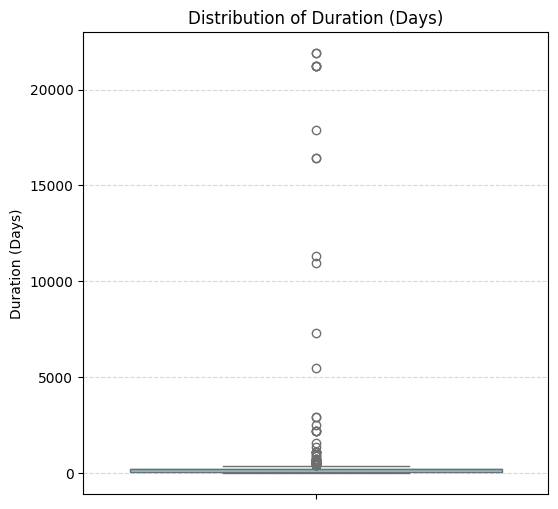

In [ ]:
# Select the duration_in_days column and drop any missing values
duration_values = df["duration_in_days"].dropna()

# Create the box plot
plt.figure(figsize=(6, 6))
sns.boxplot(y=duration_values, color="skyblue")

plt.title("Distribution of Duration (Days)")
plt.ylabel("Duration (Days)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [ ]:
# 1. Inspect stats and percentiles before clipping
print("--- Before Clipping ---")
print(duration_values.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))

--- Before Clipping ---
count     5418.000000
mean       207.043900
std        855.046322
min          0.000000
50%        210.000000
75%        210.000000
90%        210.000000
95%        210.000000
99%        387.960000
max      21900.000000
Name: duration_in_days, dtype: float64


In [ ]:
# 2. Check how many rows exceed 3,000 days
mask = df["duration_in_days"] > 3000
print(f"\nNumber of rows to be clipped (> 3000 days): {mask.sum()}")
print(f"Percentage of dataset: {mask.mean() * 100:.4f}%")


Number of rows to be clipped (> 3000 days): 13
Percentage of dataset: 0.2399%


**Why these are outliers:
As you can see in your box plot, almost all of your valid opportunities cluster densely at the bottom (with the 50th, 75th, and 90th percentiles all sitting flat at 210 days). The dots floating far up top past 5,000, 10,000, and 21,900 days are isolated extremes.**

In [ ]:
# 3. Apply the clipping threshold at 3000 days
df.loc[df["duration_in_days"] > 3000, "duration_in_days"] = 3000

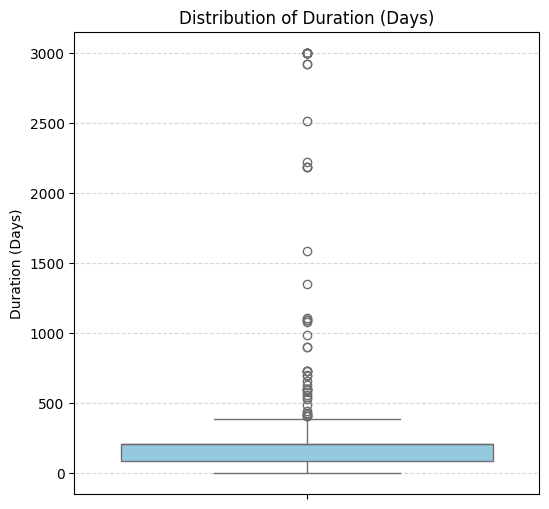

In [ ]:
# Select the duration_in_days column and drop any missing values
duration_values = df["duration_in_days"].dropna()

# Create the box plot
plt.figure(figsize=(6, 6))
sns.boxplot(y=duration_values, color="skyblue")

plt.title("Distribution of Duration (Days)")
plt.ylabel("Duration (Days)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [ ]:
df.head()

,opportunity_id,category,created_at,currency_type,fee,is_auto_approve,last_date_to_apply,location,long_description,microscholarship,modified_at,name,short_description,duration_in_days
0,Opportunity#000000000GBD0AX3Z6VYRG7R75,Competition,2022-08-08 23:06:40+00:00,USD,0.0,True,2023-07-22 04:26:40+00:00,Virtual,"Your future is in your hands, truly. Ideate an...",500.0,2023-07-22 04:26:40+00:00,Mini Saga 3.0,Express yourself in 50-words!,0.208333
1,Opportunity#000000000GFKZ4N696ZF8V2WM8,Career,2022-08-08 23:06:40+00:00,USD,0.0,True,2023-07-22 04:26:40+00:00,Virtual,At GlobalShala we believe that experiential le...,100.0,2023-07-22 04:26:40+00:00,Virtual Internship Facilitator,In this role you be impacting young lives whil...,365.000000
2,Opportunity#0000000010ZFE0ZS22FA3Q62R4,Career,2024-03-09 16:00:00+00:00,USD,0.0,False,2019-06-08 13:20:00+00:00,Virtual,Not provided,0.0,2024-03-09 16:00:00+00:00,Careerwishlist Automation 1710333189352,"Short Description, Explore hands-on defensive ...",210.000000
3,Opportunity#000000000GG34EPWZAJ6BDPQKP,Internship,2022-12-02 16:53:20+00:00,USD,0.0,True,2023-11-14 22:13:20+00:00,Virtual,"In this internship, you will help your sponsor...",1000.0,2023-07-22 04:26:40+00:00,Digital Marketing - Demo,Explore the best practices and proven strategi...,0.013889
4,Opportunity#000000000GQHDFWJ9R1HQJ4WTE,Event,2022-08-08 23:06:40+00:00,USD,0.0,True,2026-05-28 20:26:40+00:00,Virtual,As technologies such as social media apps and ...,500.0,2026-05-28 20:26:40+00:00,Humanizing Technology: An Introduction to User...,Students will learn the fundamentals of user e...,1095.000000


In [ ]:
# 1. Ensure 'created_at' is in datetime format
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")

# 2. Extract year, month, and day into separate columns
df["year"] = df["created_at"].dt.year
df["month"] = df["created_at"].dt.month
df["day"] = df["created_at"].dt.day

# Optional: Add month name for easier readability/reporting
df["month_name"] = df["created_at"].dt.strftime("%B")

# 3. Preview the updated columns
display(df[["opportunity_id", "created_at", "year", "month", "day", "month_name"]].head())

,opportunity_id,created_at,year,month,day,month_name
0,Opportunity#000000000GBD0AX3Z6VYRG7R75,2022-08-08 23:06:40+00:00,2022,8,8,August
1,Opportunity#000000000GFKZ4N696ZF8V2WM8,2022-08-08 23:06:40+00:00,2022,8,8,August
2,Opportunity#0000000010ZFE0ZS22FA3Q62R4,2024-03-09 16:00:00+00:00,2024,3,9,March
3,Opportunity#000000000GG34EPWZAJ6BDPQKP,2022-12-02 16:53:20+00:00,2022,12,2,December
4,Opportunity#000000000GQHDFWJ9R1HQJ4WTE,2022-08-08 23:06:40+00:00,2022,8,8,August


In [ ]:
# Filter for 2025 and group by month name and month number
df_2025 = df[df["year"] == 2025]

monthly_2025 = (
    df_2025.groupby(["month", "month_name"])["opportunity_id"]
    .count()
    .reset_index()
    .sort_values("month")
)

print("--- Opportunities per Month in 2025 ---")
print(monthly_2025[["month_name", "opportunity_id"]].to_string(index=False))

--- Opportunities per Month in 2025 ---
month_name  opportunity_id
  February             287
      June             186
   October             243


In [ ]:
# Filter for 2025 and group by month name and month number
df_2022 = df[df["year"] == 2022]

monthly_2022 = (
    df_2022.groupby(["month", "month_name"])["opportunity_id"]
    .count()
    .reset_index()
    .sort_values("month")
)

print("--- Opportunities per Month in 2022 ---")
print(monthly_2022[["month_name", "opportunity_id"]].to_string(index=False))

--- Opportunities per Month in 2022 ---
month_name  opportunity_id
    August              15
  December              10


In [ ]:
# Filter for 2025 and group by month name and month number
df_2023 = df[df["year"] == 2023]

monthly_2023 = (
    df_2023.groupby(["month", "month_name"])["opportunity_id"]
    .count()
    .reset_index()
    .sort_values("month")
)

print("--- Opportunities per Month in 2023 ---")
print(monthly_2023[["month_name", "opportunity_id"]].to_string(index=False))

--- Opportunities per Month in 2023 ---
month_name  opportunity_id
     March             274
      July            1045
  November             785


In [ ]:
# 1. Ensure both columns are converted to datetime (with UTC timezone handling)
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")
df["last_date_to_apply"] = pd.to_datetime(
    df["last_date_to_apply"], errors="coerce"
)

# 2. Calculate the difference in days
df["application_window_days"] = (
    df["last_date_to_apply"] - df["created_at"]
).dt.days

# 3. Preview the new column alongside the date columns
display(
    df[
        [
            "opportunity_id",
            "created_at",
            "last_date_to_apply",
            "application_window_days",
        ]
    ].head()
)

# 4. Check summary statistics (mean, median, min, max) of the application window
print(df["application_window_days"].describe())

,opportunity_id,created_at,last_date_to_apply,application_window_days
0,Opportunity#000000000GBD0AX3Z6VYRG7R75,2022-08-08 23:06:40+00:00,2023-07-22 04:26:40+00:00,347
1,Opportunity#000000000GFKZ4N696ZF8V2WM8,2022-08-08 23:06:40+00:00,2023-07-22 04:26:40+00:00,347
2,Opportunity#0000000010ZFE0ZS22FA3Q62R4,2024-03-09 16:00:00+00:00,2019-06-08 13:20:00+00:00,-1737
3,Opportunity#000000000GG34EPWZAJ6BDPQKP,2022-12-02 16:53:20+00:00,2023-11-14 22:13:20+00:00,347
4,Opportunity#000000000GQHDFWJ9R1HQJ4WTE,2022-08-08 23:06:40+00:00,2026-05-28 20:26:40+00:00,1388


count    5418.000000
mean      -74.280731
std       492.409209
min     -2547.000000
25%         0.000000
50%         0.000000
75%       115.000000
max      1504.000000
Name: application_window_days, dtype: float64


In [ ]:
print("max application_window_days is :", df['application_window_days'].max())
print("min application_window_days is :", df['application_window_days'].min())

max application_window_days is : 1504
min application_window_days is : -2547


In [ ]:
# Filter and display rows with negative application windows
negative_windows = df[df["application_window_days"] < 0]

print(f"Total negative rows: {len(negative_windows)}")
display(
    negative_windows[
        [
            "opportunity_id",
            "name",
            "created_at",
            "last_date_to_apply",
            "application_window_days",
        ]
    ]
)

Total negative rows: 357


,opportunity_id,name,created_at,last_date_to_apply,application_window_days
2,Opportunity#0000000010ZFE0ZS22FA3Q62R4,Careerwishlist Automation 1710333189352,2024-03-09 16:00:00+00:00,2019-06-08 13:20:00+00:00,-1737
8,Opportunity#0000000010YHJCSGAKECPBFQ65,Course Automation 1740727622332,2025-02-19 21:20:00+00:00,2019-06-08 13:20:00+00:00,-2084
9,Opportunity#0000000010ZNX2EXET8MGC9F7B,Careerwishlist Automation 1701751082558,2023-11-14 22:13:20+00:00,2019-06-08 13:20:00+00:00,-1621
92,Opportunity#0000000010FCVD65SWH9EDEREB,Engagement Automation 1768381468122,2026-02-02 02:40:00+00:00,2019-06-08 13:20:00+00:00,-2431
103,Opportunity#000000001008KA64Q5B4SYZAVE,Careerwishlist Automation 1714724256391,2024-03-09 16:00:00+00:00,2019-06-08 13:20:00+00:00,-1737
...,...,...,...,...,...
5388,Opportunity#0000000010YH9T244KMPQJ62DB,Course Automation 1709135518810,2024-03-09 16:00:00+00:00,2019-06-08 13:20:00+00:00,-1737
5391,Opportunity#0000000010ZZTEHSZVVQED5M1V,Engagement Role,2025-02-19 21:20:00+00:00,2023-07-22 04:26:40+00:00,-579
5395,Opportunity#0000000010YQC60E3FMCXXQTGN,Event Automation 1703237359996,2023-11-14 22:13:20+00:00,2019-06-08 13:20:00+00:00,-1621
5408,Opportunity#0000000010TZF14AAWKD0WZPRE,Event Automation 1709191993846,2024-03-09 16:00:00+00:00,2019-06-08 13:20:00+00:00,-1737


In [ ]:
negative_windows = df[df["application_window_days"] < 0]
print(f"Total negative rows: {len(negative_windows)}")

Total negative rows: 357


In [ ]:
# Average application window grouped by year
avg_by_year = (
    df.groupby("year")["application_window_days"]
    .mean()
    .reset_index()
)
print(avg_by_year)

   year  application_window_days
0  2022               522.720000
1  2023                 3.479563
2  2024              -133.145773
3  2025                -7.303073
4  2026              -278.833010


In [ ]:
# 1. Identify rows where the application window is negative (invalid dates)
invalid_mask = df["application_window_days"] < 0

# 2. Update 'last_date_to_apply' to be created_at + 30 days for those rows
df.loc[invalid_mask, "last_date_to_apply"] = df.loc[
    invalid_mask, "created_at"
] + pd.Timedelta(days=30)

# 3. Recalculate 'application_window_days' for the entire dataframe
df["application_window_days"] = (
    df["last_date_to_apply"] - df["created_at"]
).dt.days

# 4. Verify that there are no more negative rows
print(
    "Remaining negative rows after updating:",
    (df["application_window_days"] < 0).sum(),
)

# 5. Check a few of the updated rows to confirm
display(
    df[invalid_mask][
        [
            "opportunity_id",
            "name",
            "created_at",
            "last_date_to_apply",
            "application_window_days",
        ]
    ].head()
)

Remaining negative rows after updating: 0


,opportunity_id,name,created_at,last_date_to_apply,application_window_days
2,Opportunity#0000000010ZFE0ZS22FA3Q62R4,Careerwishlist Automation 1710333189352,2024-03-09 16:00:00+00:00,2024-04-08 16:00:00+00:00,30
8,Opportunity#0000000010YHJCSGAKECPBFQ65,Course Automation 1740727622332,2025-02-19 21:20:00+00:00,2025-03-21 21:20:00+00:00,30
9,Opportunity#0000000010ZNX2EXET8MGC9F7B,Careerwishlist Automation 1701751082558,2023-11-14 22:13:20+00:00,2023-12-14 22:13:20+00:00,30
92,Opportunity#0000000010FCVD65SWH9EDEREB,Engagement Automation 1768381468122,2026-02-02 02:40:00+00:00,2026-03-04 02:40:00+00:00,30
103,Opportunity#000000001008KA64Q5B4SYZAVE,Careerwishlist Automation 1714724256391,2024-03-09 16:00:00+00:00,2024-04-08 16:00:00+00:00,30


In [ ]:
print("max application_window_days is :", df['application_window_days'].max())
print("min application_window_days is :", df['application_window_days'].min())

max application_window_days is : 1504
min application_window_days is : 0


In [ ]:
avg_window = df["application_window_days"].mean()
print(f"Average Application Window (Days): {avg_window:.2f}")

Average Application Window (Days): 49.52


In [ ]:
describe_window = df["application_window_days"].describe()
print(f"Average Application Window (Days): {describe_window['mean']:.2f}")

Average Application Window (Days): 49.52


In [ ]:
# Extract the window variable and drop any nulls if present
window_values = df["application_window_days"].dropna()

# Calculate central tendency and stats
window_mean = window_values.mean()
window_median = window_values.median()
window_mode = window_values.mode()
window_max = window_values.max()
window_min = window_values.min()

# Print out the results
print(f"Mean Application Window: {window_mean:.2f} days")
print(f"Median Application Window: {window_median:.2f} days")
print(f"Mode Application Window:\n{window_mode}")
print(f"Maximum Application Window: {window_max} days")
print(f"Minimum Application Window: {window_min} days")

# Print detailed percentiles for deeper EDA
print("\n--- Detailed Percentiles ---")
print(window_values.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

Mean Application Window: 49.52 days
Median Application Window: 0.00 days
Mode Application Window:
0    0
Name: application_window_days, dtype: int64
Maximum Application Window: 1504 days
Minimum Application Window: 0 days

--- Detailed Percentiles ---
count    5418.000000
mean       49.523071
std       100.743303
min         0.000000
25%         0.000000
50%         0.000000
75%       115.000000
90%       115.000000
95%       115.000000
99%       578.000000
max      1504.000000
Name: application_window_days, dtype: float64


In [ ]:
print(df.groupby('year')['opportunity_id'].count())

year
2022      25
2023    2104
2024    2058
2025     716
2026     515
Name: opportunity_id, dtype: int64


In [ ]:
clean_fee_summary = df.groupby('year').agg(
    total_opportunities=('opportunity_id', 'count'),
    total_fee=('fee', 'sum'),
    average_fee=('fee', 'mean'),
    Total_duration_days=('duration_in_days', 'sum'),
    Average_Duration=('duration_in_days', 'mean'),
    total_microscholarship=('microscholarship', 'sum'),
    avg_microscholarship=('microscholarship', 'mean')
).reset_index()

display(clean_fee_summary)

,year,total_opportunities,total_fee,average_fee,Total_duration_days,Average_Duration,total_microscholarship,avg_microscholarship
0,2022,25,2725.0,109.000000,23736.302083,949.452083,13821.0,552.840000
1,2023,2104,17886.0,8.500951,361546.184028,171.837540,361628.0,171.876426
2,2024,2058,17811.0,8.654519,369485.282639,179.536095,365798.0,177.744412
3,2025,716,8425.0,11.766760,88100.242361,123.045031,59618.0,83.265363
4,2026,515,6041.0,11.730097,103461.838889,200.896775,87017.0,168.965049


In [ ]:
# Create a cross-tabulation of Year vs Month
monthly_breakdown = pd.crosstab(df['year'], df['month'])
print("--- Opportunities per Year and Month ---")
display(monthly_breakdown)

--- Opportunities per Year and Month ---


month,2,3,5,6,7,8,10,11,12
year,,,,,,,,,
2022,0,0,0,0,0,15,0,0,10
2023,0,274,0,0,1045,0,0,785,0
2024,0,957,0,0,503,0,598,0,0
2025,287,0,0,186,0,0,243,0,0
2026,457,0,58,0,0,0,0,0,0


In [ ]:
# Convert specific numeric columns explicitly
numeric_cols = ['duration_in_days', 'fee', 'microscholarship']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Describe all numeric columns
df.select_dtypes(include='number').describe()

,fee,microscholarship,duration_in_days,year,month,day,application_window_days
count,5418.000000,5418.000000,5418.000000,5418.000000,5418.000000,5418.000000,5418.000000
mean,9.761536,163.876338,174.664055,2023.924695,6.406054,14.955334,49.523071
std,101.379599,394.372544,189.544659,0.955854,3.249421,8.529301,100.743303
min,0.000000,0.000000,0.000000,2022.000000,2.000000,2.000000,0.000000
25%,0.000000,100.000000,84.250000,2023.000000,3.000000,9.000000,0.000000
50%,0.000000,120.000000,210.000000,2024.000000,7.000000,14.000000,0.000000
75%,0.000000,120.000000,210.000000,2024.000000,10.000000,22.000000,115.000000
max,3000.000000,4480.000000,3000.000000,2026.000000,12.000000,28.000000,1504.000000


In [ ]:
df_cleaned = df.copy()

# Convert date columns to datetime data type
date_cols = ['created_at', 'last_date_to_apply', 'modified_at']
for col in date_cols:
    df_cleaned[col] = pd.to_datetime(df_cleaned[col], errors='coerce')

# Select the columns using single brackets
df_cleaned[date_cols].head()

,created_at,last_date_to_apply,modified_at
0,2022-08-08 23:06:40+00:00,2023-07-22 04:26:40+00:00,2023-07-22 04:26:40+00:00
1,2022-08-08 23:06:40+00:00,2023-07-22 04:26:40+00:00,2023-07-22 04:26:40+00:00
2,2024-03-09 16:00:00+00:00,2024-04-08 16:00:00+00:00,2024-03-09 16:00:00+00:00
3,2022-12-02 16:53:20+00:00,2023-11-14 22:13:20+00:00,2023-07-22 04:26:40+00:00
4,2022-08-08 23:06:40+00:00,2026-05-28 20:26:40+00:00,2026-05-28 20:26:40+00:00


In [ ]:
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Verify the updated data types
print(df_cleaned.info())
print("data frame shape is: ", df_cleaned.shape)
df_cleaned.head()


# 1. Ensure 'created_at' is in datetime format and extract the year
df_cleaned["created_at"] = pd.to_datetime(df_cleaned["created_at"], errors="coerce")
df_cleaned["year"] = df_cleaned["created_at"].dt.year

# 2. Group by year and calculate the sum for fee and microscholarship
yearly_financials = (
    df_cleaned.groupby("year")[["fee", "microscholarship", "duration_in_days"]]
    .sum()
    .reset_index()
)

# Display the result
print(yearly_financials)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5418 entries, 0 to 5417
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype              
---  ------                   --------------  -----              
 0   opportunity_id           5418 non-null   object             
 1   category                 5418 non-null   object             
 2   created_at               5418 non-null   datetime64[ns, UTC]
 3   currency_type            5418 non-null   object             
 4   fee                      5418 non-null   float64            
 5   is_auto_approve          5418 non-null   bool               
 6   last_date_to_apply       5418 non-null   datetime64[ns, UTC]
 7   location                 5418 non-null   object             
 8   long_description         5418 non-null   object             
 9   microscholarship         5418 non-null   float64            
 10  modified_at              5418 non-null   datetime64[ns, UTC]
 11  name                     5418 

In [ ]:
df_cleaned.head()

,opportunity_id,category,created_at,currency_type,fee,is_auto_approve,last_date_to_apply,location,long_description,microscholarship,modified_at,name,short_description,duration_in_days,year,month,day,month_name,application_window_days
0,Opportunity#000000000GBD0AX3Z6VYRG7R75,Competition,2022-08-08 23:06:40+00:00,USD,0.0,True,2023-07-22 04:26:40+00:00,Virtual,"Your future is in your hands, truly. Ideate an...",500.0,2023-07-22 04:26:40+00:00,Mini Saga 3.0,Express yourself in 50-words!,0.208333,2022,8,8,August,347
1,Opportunity#000000000GFKZ4N696ZF8V2WM8,Career,2022-08-08 23:06:40+00:00,USD,0.0,True,2023-07-22 04:26:40+00:00,Virtual,At GlobalShala we believe that experiential le...,100.0,2023-07-22 04:26:40+00:00,Virtual Internship Facilitator,In this role you be impacting young lives whil...,365.000000,2022,8,8,August,347
2,Opportunity#0000000010ZFE0ZS22FA3Q62R4,Career,2024-03-09 16:00:00+00:00,USD,0.0,False,2024-04-08 16:00:00+00:00,Virtual,Not provided,0.0,2024-03-09 16:00:00+00:00,Careerwishlist Automation 1710333189352,"Short Description, Explore hands-on defensive ...",210.000000,2024,3,9,March,30
3,Opportunity#000000000GG34EPWZAJ6BDPQKP,Internship,2022-12-02 16:53:20+00:00,USD,0.0,True,2023-11-14 22:13:20+00:00,Virtual,"In this internship, you will help your sponsor...",1000.0,2023-07-22 04:26:40+00:00,Digital Marketing - Demo,Explore the best practices and proven strategi...,0.013889,2022,12,2,December,347
4,Opportunity#000000000GQHDFWJ9R1HQJ4WTE,Event,2022-08-08 23:06:40+00:00,USD,0.0,True,2026-05-28 20:26:40+00:00,Virtual,As technologies such as social media apps and ...,500.0,2026-05-28 20:26:40+00:00,Humanizing Technology: An Introduction to User...,Students will learn the fundamentals of user e...,1095.000000,2022,8,8,August,1388


In [ ]:
df_cleaned.head(3)

,opportunity_id,category,created_at,currency_type,fee,is_auto_approve,last_date_to_apply,location,long_description,microscholarship,modified_at,name,short_description,duration_in_days,year,month,day,month_name,application_window_days
0,Opportunity#000000000GBD0AX3Z6VYRG7R75,Competition,2022-08-08 23:06:40+00:00,USD,0.0,True,2023-07-22 04:26:40+00:00,Virtual,"Your future is in your hands, truly. Ideate an...",500.0,2023-07-22 04:26:40+00:00,Mini Saga 3.0,Express yourself in 50-words!,0.208333,2022,8,8,August,347
1,Opportunity#000000000GFKZ4N696ZF8V2WM8,Career,2022-08-08 23:06:40+00:00,USD,0.0,True,2023-07-22 04:26:40+00:00,Virtual,At GlobalShala we believe that experiential le...,100.0,2023-07-22 04:26:40+00:00,Virtual Internship Facilitator,In this role you be impacting young lives whil...,365.000000,2022,8,8,August,347
2,Opportunity#0000000010ZFE0ZS22FA3Q62R4,Career,2024-03-09 16:00:00+00:00,USD,0.0,False,2024-04-08 16:00:00+00:00,Virtual,Not provided,0.0,2024-03-09 16:00:00+00:00,Careerwishlist Automation 1710333189352,"Short Description, Explore hands-on defensive ...",210.000000,2024,3,9,March,30


In [ ]:
# from google.colab import files

# # Strip timezone info so Excel can accept the dates without throwing errors
# date_cols = ['created_at', 'last_date_to_apply', 'modified_at']
# for col in date_cols:
#     if col in df_cleaned.columns and pd.api.types.is_datetime64tz_dtype(df_cleaned[col]):
#         df_cleaned[col] = df_cleaned[col].dt.tz_localize(None)

# # Export to an Excel file successfully
# df_cleaned.to_excel('data_studio.xlsx', index=False)

# # Trigger the download in Colab with the matching filename
# files.download('data_studio.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# from google.colab import files

# # Strip timezone info so Excel can accept the dates
# date_cols = ['created_at', 'last_date_to_apply', 'modified_at']
# for col in date_cols:
#     if col in df_cleaned.columns and pd.api.types.is_datetime64tz_dtype(df_cleaned[col]):
#         df_cleaned[col] = df_cleaned[col].dt.tz_localize(None)

# # Now export to Excel successfully
# df_cleaned.to_excel('Cleaned_Opportunity_Dataset.xlsx', index=False)

# # Trigger download
# files.download('Cleaned_Opportunity_Dataset.xlsx')

In [ ]:
# # 1. Group by year to check counts, totals, and averages for fees and microscholarships
# yearly_analysis = df.groupby('year').agg(
#     opportunity_count=('opportunity_id', 'count'),
#     total_fee=('fee', 'sum'),
#     avg_fee=('fee', 'mean'),
#     total_microscholarship=('microscholarship', 'sum'),
#     avg_microscholarship=('microscholarship', 'mean')
# ).reset_index()

# print("--- Yearly Financial and Opportunity Breakdown ---")
# display(yearly_analysis)

# # 2. Check the date range (min and max created_at) for the drop years to identify partial data
# print("\n--- Date Range Check for 2026 ---")
# print(df[df['year'] == 2026]['created_at'].agg(['min', 'max']))

# # 3. Visualization: Side-by-side comparison of Counts vs Total Financials
# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# # Plot 1: Opportunity Count per Year
# sns.barplot(data=yearly_analysis, x='year', y='opportunity_count', ax=axes[0], palette='Blues_d')
# axes[0].set_title('Number of Opportunities Created per Year')
# axes[0].set_xlabel('Year')
# axes[0].set_ylabel('Count')

# # Plot 2: Total Microscholarships per Year
# sns.barplot(data=yearly_analysis, x='year', y='total_microscholarship', ax=axes[1], palette='Oranges_d')
# axes[1].set_title('Total Microscholarships per Year')
# axes[1].set_xlabel('Year')
# axes[1].set_ylabel('Total Amount')

# plt.tight_layout()
# plt.show()

In [ ]:
# # 2. Grouped Summary Table (Duration by Location and Category)
# summary_table = (
#     df.groupby(["location", "category"])["duration_in_days"]
#     .agg(
#         Average_Duration="mean",
#         Median_Duration="median",
#         Min_Duration="min",
#         Max_Duration="max",
#     )
#     .reset_index()
# )

# print("--- Grouped Summary Table of Duration (Days) ---")
# display(summary_table)

# # 3. Pivot Table for Visualizations (using Average Duration)
# pivot_avg = df.pivot_table(
#     index="location",
#     columns="category",
#     values="duration_in_days",
#     aggfunc="mean",
# )

# # 4. Visualization A: Heatmap of Location × Category (Average Duration)
# plt.figure(figsize=(10, 6))
# sns.heatmap(pivot_avg, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Average Duration (Days)"})
# plt.title("Heatmap: Average Duration by Location × Category", fontsize=14)
# plt.xlabel("Category", fontsize=12)
# plt.ylabel("Location", fontsize=12)
# plt.xticks(rotation=45, ha="right")
# plt.tight_layout()
# plt.show()

# # 5. Visualization B: Grouped Bar Chart of Location × Category
# fig, ax = plt.subplots(figsize=(12, 6))
# pivot_avg.plot(kind="bar", ax=ax, width=0.8, edgecolor="black")
# plt.title("Grouped Bar Chart: Average Duration by Location and Category", fontsize=14)
# plt.xlabel("Location", fontsize=12)
# plt.ylabel("Average Duration (Days)", fontsize=12)
# plt.xticks(rotation=0)
# plt.legend(title="Category", bbox_to_anchor=(1.05, 1), loc="upper left")
# plt.grid(axis="y", linestyle="--", alpha=0.6)
# plt.tight_layout()
# plt.show()

In [ ]:
# # 1. Ensure 'year' is present and calculate yearly sums
# df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")
# df["year"] = df["created_at"].dt.year

# yearly_financials = (
#     df.groupby("year")[["fee", "microscholarship"]]
#     .sum()
#     .reset_index()
# )

# # Convert year to string for clean categorical plotting
# yearly_financials["year"] = yearly_financials["year"].astype(str)

# # 2. Create the dual-axis chart
# fig, ax1 = plt.subplots(figsize=(7, 5))

# # Primary Y-axis: Bar chart for Fee
# color = "tab:blue"
# ax1.set_xlabel("Year", fontsize=12)
# ax1.set_ylabel("Total Fee", color=color, fontsize=12)
# ax1.bar(yearly_financials["year"], yearly_financials["fee"], color=color, alpha=0.6, width=0.4, label="Fee (Bar)")
# ax1.tick_params(axis="y", labelcolor=color)

# # Secondary Y-axis: Line chart for Microscholarship
# ax2 = ax1.twinx()
# color = "tab:orange"
# ax2.set_ylabel("Total Microscholarship", color=color, fontsize=12)
# ax2.plot(yearly_financials["year"], yearly_financials["microscholarship"], color=color, marker="o", linewidth=2.5, label="Microscholarship (Line)")
# ax2.tick_params(axis="y", labelcolor=color)

# plt.title("Year-wise Trend: Total Fee (Columns) and Microscholarship (Line)", fontsize=14)
# fig.tight_layout()
# plt.show()

In [ ]:
# # Extract Month Number and Month Name
# df_cleaned["month_number"] = df_cleaned["created_at"].dt.month
# df_cleaned["month_name"] = df_cleaned["created_at"].dt.strftime("%B")

# # Group, count, and sort chronologically by month number
# monthly_table = (
#     df_cleaned.groupby(["month_number", "month_name"])["opportunity_id"]
#     .count()
#     .reset_index()
#     .sort_values("month_number")[["month_name", "opportunity_id"]]
# )

# print(monthly_table.to_string(index=False))

In [ ]:
# # Ensure 'created_at' is in datetime format
# df_cleaned["created_at"] = pd.to_datetime(
#     df_cleaned["created_at"], errors="coerce"
# )

# # Extract Month Number and Month Name
# df_cleaned["month_number"] = df_cleaned["created_at"].dt.month
# df_cleaned["month_name"] = df_cleaned["created_at"].dt.strftime("%B")

# # Group and count opportunities per month
# monthly_counts = (
#     df_cleaned.groupby(["month_number", "month_name"])["opportunity_id"]
#     .count()
#     .reset_index()
# )

# # Sort chronologically by month number (1 to 12)
# monthly_counts = monthly_counts.sort_values("month_number")

# # Plotting as a trend line chart (or change to sns.barplot if you prefer bars)
# plt.figure(figsize=(12, 6))
# sns.lineplot(
#     data=monthly_counts,
#     x="month_name",
#     y="opportunity_id",
#     marker="o",
#     color="b",
#     linewidth=2.5,
# )

# plt.title("Number of Opportunities Created per Month", fontsize=14)
# plt.xlabel("Month", fontsize=12)
# plt.ylabel("Number of Opportunities", fontsize=12)
# plt.xticks(rotation=45)
# plt.grid(True, linestyle="--", alpha=0.6)
# plt.tight_layout()
# plt.show()

# Exploratory data analysis

In [ ]:
# # Ensure 'created_at' is in datetime format
# df_cleaned["created_at"] = pd.to_datetime(
#     df_cleaned["created_at"], errors="coerce"
# )

# # Extract Year only for grouping
# df_cleaned["year"] = df_cleaned["created_at"].dt.year

# # Count the number of opportunities per year
# yearly_counts = (
#     df_cleaned.groupby("year")["opportunity_id"].count().reset_index()
# )

# # Convert year to string for clean plotting
# yearly_counts["year"] = yearly_counts["year"].astype(str)

# # Plotting
# plt.figure(figsize=(10, 6))
# sns.barplot(data=yearly_counts, x="year", y="opportunity_id", color="skyblue")

# plt.title("Number of Opportunities Created per Year", fontsize=14)
# plt.xlabel("Year", fontsize=12)
# plt.ylabel("Number of Opportunities", fontsize=12)
# plt.tight_layout()
# plt.show()

In [ ]:
# # Count the number of opportunities per category
# category_counts = (
#     df_cleaned.groupby("category")["opportunity_id"].count().reset_index()
# )

# # Sort values for a cleaner, descending bar chart (optional)
# category_counts = category_counts.sort_values(
#     by="opportunity_id", ascending=False
# )

# # Plotting
# plt.figure(figsize=(12, 6))
# sns.barplot(
#     data=category_counts, x="category", y="opportunity_id", color="skyblue"
# )

# plt.title("Number of Opportunities per Category", fontsize=14)
# plt.xlabel("Category", fontsize=12)
# plt.ylabel("Number of Opportunities", fontsize=12)
# plt.xticks(rotation=45, ha="right")
# plt.tight_layout()
# plt.show()